In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
import matplotlib.pyplot as plt
import optuna
import time
import numpy as np
from tabulate import tabulate

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestClassifier


from torch.utils.data import DataLoader, random_split, Subset
from torchvision import datasets, transforms
import torchvision
import torchvision.transforms as transforms

from optuna.trial import TrialState

Learning Outcomes: After completing this notebook, you will be able to:

- Explain what is Optuna.
- Why it was create and what problems it solve.
- Optuna Core Concepts
- How to use Optuna inside the code
- Optuna Dashboard

# Part 0: Hyperparameter Tuning - The problem

### 0.0: What is model hyperparameter and how they differ from model parameters:

  In any model there are two types of variables, parameter which are internal configuration variables that the model learn directly from the training data during training, while hyperparameters are external configuration variables whose values are set manually before the training process begins and it dedicate how the model learns. The following table shows the key differences between them:

|Feature | Parameters | Hyperparameter |
|---|---|---|
|Origin | learned automatically from data | Set manually by user or engine |
|Determination Time | During training | Before Training |
|Can they change during training? | Yes, Updates continuously | Usually remain fixed |
|Examples | Weights , Biases | Learning rate, batch size, number of epochs, layer depth |


### 0.1: What is hyperparameters tuning?

  Is the process of finding the best set of configuration settings for a machine learning model before training it to maximize its performance or to make it perform well on unseen data.

Why we need hyperparameters tuning?

  Because different hyperparameters values dramatically affect model's performance (accuracy, stability, and generalization), so we need to find the set values that make the model perform as we want before training it.
  
  Here is an example that shows how different learning values can affect the model performance:
  If the learning rate is too high: The model might overshoot the optimal solution and never converge.
  If the learning rate is too low: The model will take forever to train and might get stuck in a sub-optimal trap (Local Minimum).


Too High (1.0)
Epochs: 79
Training time: 0.1315 seconds
Final loss: inf

Reasonable (0.05)
Epochs: 29
Training time: 0.0070 seconds
Final loss: 0.049363

Too Low (0.0001)
Epochs: 500
Training time: 0.1079 seconds
Final loss: 11.040000


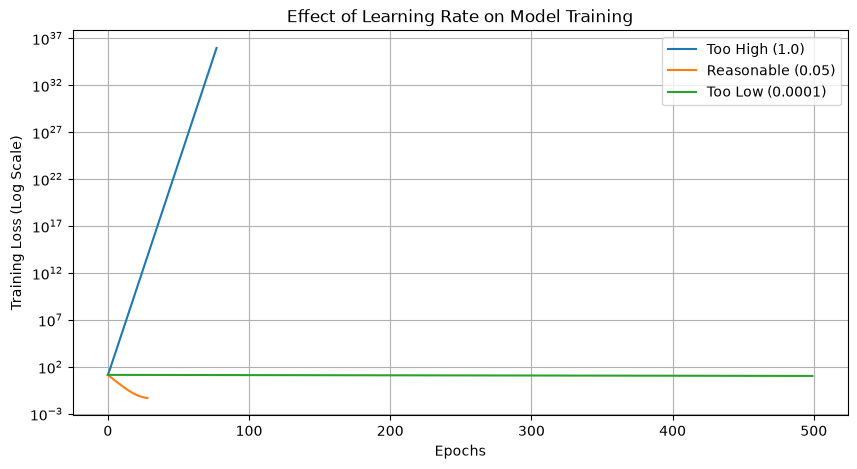

In [3]:
# 1. Create a simple dataset: y = 3x + 2
torch.manual_seed(42)

X = torch.linspace(-2, 2, 300).reshape(-1, 1)
y = 3 * X + 2 + 0.2 * torch.randn_like(X)

# 2. Define three learning rates
learning_rates = {
    "Too High (1.0)": 1.0,
    "Reasonable (0.05)": 0.05,
    "Too Low (0.0001)": 0.0001
}

results = {}

# 3. Train the same model using each learning rate
for name, lr in learning_rates.items():

    torch.manual_seed(0)

    model = torch.nn.Linear(1, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_function = torch.nn.MSELoss()

    losses = []
    start_time = time.perf_counter()

    for epoch in range(500):

        optimizer.zero_grad()

        predictions = model(X)
        loss = loss_function(predictions, y)

        loss.backward()
        optimizer.step()

        losses.append(loss.item())

        # Stop if training diverges
        if not torch.isfinite(loss):
            break

        # Stop when the model reaches the target loss
        if loss.item() < 0.05:
            break

    elapsed_time = time.perf_counter() - start_time

    results[name] = {
        "losses": losses,
        "epochs": len(losses),
        "time": elapsed_time,
        "final_loss": losses[-1]
    }

    print(f"\n{name}")
    print(f"Epochs: {len(losses)}")
    print(f"Training time: {elapsed_time:.4f} seconds")
    print(f"Final loss: {losses[-1]:.6f}")

# 4. Visualize the learning curves
plt.figure(figsize=(10, 5))

for name, result in results.items():

    # Keep only finite loss values
    valid_losses = [
        loss for loss in result["losses"]
        if torch.isfinite(torch.tensor(loss))
    ]

    plt.plot(valid_losses, label=name)

plt.yscale("log")

plt.xlabel("Epochs")
plt.ylabel("Training Loss (Log Scale)")
plt.title("Effect of Learning Rate on Model Training")

plt.legend()
plt.grid(True)
plt.show()


### 0.2: Early techniques used to perform hyperparameters:

**0.2.1: Manual Search (Oldest Technique):**

This is the earliest and simplest approach. The machine learning engineer chooses hyperparameters based on experience, trains the model, observes the results, and adjusts them iteratively. This process relies entirely on human intuition.

Advantages:
- Simple.
- No additional tools required.
- Helps beginners understand the effect of each hyperparameter.
  
Disadvantages:
- Time-consuming.
- Depends heavily on experience.
- Can easily miss the best hyperparameter values.

**0.2.2: Grid Search (Traditional Standard):**

Grid search systematically test all the combinations for all the possible values for all the hyperparameters. So we define a fixed grid of values for each hyperparameter, and the algorithm tests every single possible combination (the Cartesian product).

For example is we want to tune the following:

Learning Rate = [0.1, 0.01, 0.001]

Batch Size = [16, 32, 64]

Optimizer = [SGD, Adam]

The Grid Search tests every combination:

|Trial | Learning Rate | Batch Size | Optimizer |
|---|---|---|---|
| 1	| 0.1 | 16 | SGD |
|2 | 0.1 | 16 | Adam |
|3 | 0.1 | 32 | SGD |
|... | ... | ... | ... |
|18 | 0.001 | 64 | Adam |

Advantages:

- Very easy to implement.
- Guaranteed to test every specified combination.
- Good when there are only a few hyperparameters.

Disadvantages:

- It suffers heavily from combinatorial explosion. Adding parameters or finer value increments causes the number of required training runs to skyrocket into thousands or millions.
  
  For example if we have 6 hyperparameters, and each has 10 values, then the grid search must perform 10⁶ = 1,000,000.

**0.2.3: Random Search (Blind Sampling):**

Instead of checking every point on a rigid grid, the engineer define statistical distributions (or a pool of choices) for each parameter, and the algorithm randomly selects a fixed number of combinations to test. The main problem in this search is that there is no memory from previous trails about what went right or wrong so the algorithm may repeat it again, this is called blind search.

Advantages:

- Much faster than Grid Search.
- Explores more of the search space.
- Works well in high-dimensional problems.

Disadvantages:

- Still random.
- May miss the optimum.
- Does not learn from previous trials.

# Part 1: The need for Optuna:

As traditional hyperparameter tuning approaches have limitations like:
- Grid Search can require an enormous number of experiments.
- Random Search does not learn from previous trials.
- Manual tuning depends heavily on human experience.
- Deep learning experiments can consume substantial computational resources.

optuna was developed to handle these limitations as we will see.

### 1.1: What is Optuna?
Optuna is a framework for finding the optimal hyperparameter values by trial and error for higher-excellent performance. It employs a Bayesian Optimization algorithm called Tree-structured Parzen Estimator.

We can also define Optuna as tool used to orchestrate the experiment process to find the optimum set of hyperparameters values. It
```
- Suggests hyperparameters
- Runs your objective function
- Receives the result
- Records the result
- Decides what to try next
- Repeats
- Keeps the best configuration
```

### 1.2: How it differ from old techniqus?
Optuna sits between brute‑force and full Bayesian frameworks. It provides intelligent samplers (e.g., TPE, CMA‑ES) that learn from past trials (intelligent hyperparameter sampling), supports pruning (stop bad trials early), and allows expressive, conditional search spaces defined inside the objective function.

### 1.3: How TPE (Default Optuna algorithm) works?

Let us see how Optuna tackled the problems faced by previous techniques:

Optuna use a method called Tree-Structured Parzen Estimator which is probabilistic sampling algorithm. Let us understand the names first then get deeper in how it works:

| Word | Meaning | Explanation |
|---|---|---|
| Tree-structured | Supports conditional and hierarchical search spaces. | Some hyperparameters depend on other hyperparameters. |
| Parzen | Uses probability density estimation. | Estimates where good and bad hyperparameter values are likely to occur. |
| Estimator | Estimates probability distributions from observed data. | Uses previous trial results to guide future hyperparameter suggestions. |

So here instead of trying every combination or randomly select them, we run n number of trails, then model "good" vs "bad" trails distribution, so it can answer two questions:
 1. What parameter values are associated with good performance?
 2. What parameter values are associated with poor performance?

So instead of predicting the performance, it focus on the good trails distribution and ask wehtehr the hyperparameter value belongs to the distribution. In other words, it look if the hyperparameter look similar to the hyperparameters that have already produced good results.

This is how it mathimatically models the two probability distributions:

probability distribution of promising parameter values: l(x)=p(x\mid y < y^*)

probability distribution of less promising parameter values: g(x)=p(x\mid y >= y^*)

Where:
- x = hyperparameter values.
- y = objective value (such as validation loss).
- y^* = a threshold separating good and bad trials.

So far this is for the candidates we already have for the the first n trials, then for the next candidate hyperparameter value TPE samples its values from the good distribution l(x) by using this ratio:

   l(x) / g(x)

A higher ratio indicates that a candidate is much more likely under the good distribution than under the bad distribution.

Note: You might be thinking well if all techniques will need the same number of trails or initial trails then why to use Optuna?! The advantage of Optuna's TPE is not necessarily performing fewer trials. It is making better use of the information collected from previous trials.

**So in clear steps we can say that Optuna (TPE) works as follows:**

  1. Initial Random Trials (Warm-up):
     
     Before building any statistical model, Optuna runs a few initial trials (controlled by n_startup_trials, usually set to 10) using purely random sampling. This builds an initial baseline dataset of parameters and their corresponding performance scores.
     
  2. Splitting the results (good VS bad):
 
     Once enough trials are complete, Optuna splits the history into two distinct groups based on a threshold (often determined by a percentile parameter called $\gamma$, e.g., the top 20% vs. the remaining 80%).
     - Group 1: Configurations that yielded good (low error / high accuracy) results.
     - Group 2: Configurations that yielded bad results.
     
  3. Building the Distributions (l(x) and g(x))
  4. 
     Following the Bayesian approach, Optuna fits probability density functions (often using Gaussian Mixture Models) to both groups:

     l(x) = P(x \ y < y*): The probability distribution of parameters (x) given that the score (y) is better than the threshold (y*) (the "good" distribution).
     
     g(x) = P(x \ y >= y*): The probability distribution of parameters (x) for the remaining trials (the "bad" distribution).
     
  6. Choose the next trail values: The model set values and compute the ratio for them using l(x) / g(X) to see from which distribution it will come.

### 1.4: Core Cocepts:

#### 1. Study:
- Study represents a single optimization task or experiment, serving as the central container for managing the entire hyperparameter tuning process.
- Think of it as a project or experiment that manages multiple training attempts.
- Inside it we define the study name and the goal of the optimization task (like we want to minimize or maximize a function so it choose the values based on it.)
- It keeps track of:
    - All trials.
    - Suggested parameters.
    - Objective values.
    - Best trial.
    - Optimization history.

#### 2. Trial:
- A Trial represents one experiment within a Study.
- Each trial contains:
    - Suggested hyperparameter values.
    - The objective value returned by the function.
    - Its state (complete, pruned, failed, etc.).
    - Additional metadata.

- For example suppose we want to train a Random Forest five times with different hyperparameters:

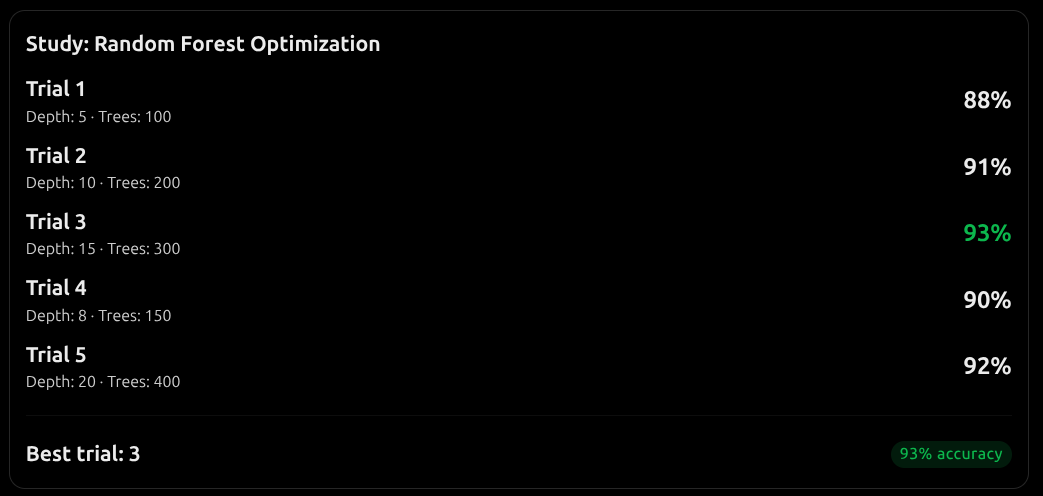

#### 3. Objective Function
- The objective function defines what Optuna should optimize.
- It tells Optuna:
    1. Which hyperparameters to suggest.
    2. How to train the model.
    3. How to evaluate the model.
    4. Which metric to return.
For example:

```
def objective(trial):

    max_depth = trial.suggest_int(
        "max_depth", 2, 30
    )

    n_estimators = trial.suggest_int(
        "n_estimators", 50, 500
    )

    model = RandomForestClassifier(
        max_depth=max_depth,
        n_estimators=n_estimators
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_valid)

    accuracy = accuracy_score(
        y_valid, predictions
    )

    return accuracy

```

#### 4. Sampler
- The sampler decides which hyperparameter values Optuna should try next. The defult is TPE but there are other samplers you can choose from.

    |Sampler | Description |
    |---|---|
    |BaseSampler | Base class for samplers. |
    |RandomSampler | Sampler using random sampling. |
    |TPESampler | Sampler using TPE (Tree-structured Parzen Estimator) algorithm. |
    |GPSampler | Sampler using Gaussian process-based Bayesian optimization. |
    |CmaEsSampler | A sampler using CMA-ES as the backend. |
    |NSGAIISampler | Multi-objective sampler using the NSGA-II algorithm. |
    |NSGAIIISampler | Multi-objective sampler using the NSGA-III algorithm. |
    |GridSampler | Sampler that performs exhaustive search over user-specified grids. |
    |QMCSampler | A Quasi Monte Carlo sampler that generates low-discrepancy sequences. |
    |BruteForceSampler | Sampler that performs exhaustive search over the define-by-run search space. |
    |PartialFixedSampler | Sampler with partially fixed parameters. |

#### 5. Pruner
- The pruner decides whether a trial should stop early because its intermediate performance is unpromising.

- The pruner compares intermediate results according to its pruning strategy.

- It may stop a trail because its performance is substantially worse than the reference trials, not just becuase its accuracy is getting worst.

- Common Optuna pruners:

    |Pruner | How it works |
    |--- | --- |
    |MedianPruner | Compares intermediate performance against the median of previous completed trials. |
    |PercentilePruner | Compares against a selected percentile of previous trials. |
    |SuccessiveHalvingPruner | Repeatedly eliminates weaker trials and allocates more resources to promising ones. |
    |HyperbandPruner | Uses multiple successive-halving brackets with different resource allocations. |
    |NopPruner | Disables pruning. |

#### 6. Search Space:
- A search space defines which hyperparameters Optuna can change and the possible values it can choose.

- Optuna provides three main suggestion methods.

    | Method | Purpose | Example |
    |---|---|---|
    | suggest_int() | Integer values | Number of trees |
    | suggest_float() | Decimal values | Learning rate |
    | suggest_categorical() | Choices from a list | Optimizer type |

Let us see how we use them inside the code:

6.1. Integer Hyperparameter:

        n_estimators = trial.suggest_int(
            "n_estimators",
            50,
            500
        )

        Optuna chooses an integer values for the hyperparameter between 50 and 500.

6.2. Float Hyperparameter:

        learning_rate = trial.suggest_float(
            "learning_rate",
            0.0001,
            0.1,
            log=True
        )

        Optuna chooses a decimal value between 0.0001 and 0.1.

6.3. Categorical Hyperparameter:

        optimizer = trial.suggest_categorical(
            "optimizer",
            ["Adam", "SGD", "RMSprop"]
        )

        Optuna chooses one of the available options.

#### 7. Conditional Search Space:

Imagin you want to choose between models that each has different hyperparameters. For example:

        def objective(trial):

            model_name = trial.suggest_categorical(
                "model",
                ["RandomForest", "SVM"]
            )

            if model_name == "RandomForest":

                max_depth = trial.suggest_int(
                    "max_depth", 2, 30
                )

                # Build Random Forest

            else:

                C = trial.suggest_float(
                    "C", 0.001, 100, log=True
                )

                # Build SVM

If Optuna selects Random Forest, it suggests max_depth. If it selects SVM, it suggests C.

This is also called a define-by-run search space: the search space can be constructed dynamically using ordinary Python logic.

### 8. Storage:

Storage is the component responsible for saving and retrieving information about optimization trials. If you use the default in-memory storage, the study information exists only in the running Python process. When that process ends, the in-memory study is lost. 

Types of Storage in Optuna:

|Storage type | Description | Persistence |
|---|---|---|
|InMemoryStorage | Stores trial information in computer memory (RAM) when you create a study without specifying storage| Lost when the process ends |
|JournalStorage | Stores trial information in a journal log. | Persistent when configured with a persistent journal backend |
|RDBStorage | Stores trial information in a relational database. | Persistent |


### 9. FrozenTrial

A FrozenTrial is an object representing the recorded information about one trial.

Think of it as a snapshot of a trial's information.

When Optuna finishes or records a trial, it can represent that trial using a FrozenTrial object.

Optuna records the information about that trial, including its parameters, objective value, state, and other metadata.

The resulting FrozenTrial object gives you access to this recorded information.

Trail VS FrozenTrial: 

A trial works when the object is passed to the objective function. It lets Optuna suggest hyperparameters, report intermediate values, and check whether a trial should be pruned (Interact with a trial while it runs). While FrozenTrail is a representation of the trial's recorded information, it's used to inspect parameters, results, state, and metadata (Represent recorded trial information).

A FrozenTrial can contain several important attributes:

|Attribute | Meaning | Example |
|---|---|---|
|number | Trial's sequential number within the study. | 0 |
|params | Hyperparameter values used in the trial. | {"max_depth": 10} |
|value | Single objective value. | 0.87 |
|values | Objective values, especially useful for multi-objective studies. | [0.87, 0.12] |
|state | Current recorded state of the trial. | COMPLETE  |
|datetime_start | When the trial started. | Start timestamp |
|datetime_complete | When the trial completed. | Completion timestamp |
|duration | How long the trial took. | 0:00:03 |
|user_attrs |Additional information saved by the user. | {"model": "RandomForest"} |
|intermediate_values | Intermediate objective values reported during the trial. | {0: 0.65, 1: 0.72} |

### 1.5: Code Example 1: The "Hello World" of Optuna

In [ ]:
# 1. Define the Objective Function
def objective(trial):
    # Suggest hyperparameters dynamically
    x = trial.suggest_float('x', -10, 10)
    y = trial.suggest_float('y', -10, 10)
    
    # The function we want to minimize: (x - 2)^2 + (y + 3)^2
    # Minimum is at x=2, y=-3
    return (x - 2)**2 + (y + 3)**2

# 2. Create a Study object (direction='minimize' or 'maximize')
study = optuna.create_study(direction='minimize', study_name='math_function')

# 3. Run the optimization, This is where optuna actually start to work
study.optimize(objective, n_trials=100)

# 4. Inspect the results
print(f"Best trial value: {study.best_trial.value:.4f}") # Returns the objective value of the best trial.
print(f"Best parameters: {study.best_trial.params}") # Returns the parameter values associated with the best trial.

[I 2026-11-21 17:18:34,074] A new study created in memory with name: math_function
[I 2026-11-21 17:18:34,076] Trial 0 finished with value: 56.299548930496854 and parameters: {'x': -1.4447882182061473, 'y': -9.665807007572674}. Best is trial 0 with value: 56.299548930496854.
[I 2026-11-21 17:18:34,078] Trial 1 finished with value: 96.69054077708816 and parameters: {'x': 4.453893434726071, 'y': 6.522024353471085}. Best is trial 0 with value: 56.299548930496854.
[I 2026-11-21 17:18:34,079] Trial 2 finished with value: 101.58742481628876 and parameters: {'x': -7.984662584776889, 'y': -1.623795842018609}. Best is trial 0 with value: 56.299548930496854.
[I 2026-11-21 17:18:34,080] Trial 3 finished with value: 29.823355794797987 and parameters: {'x': 6.8804554111032985, 'y': -0.5495896721098887}. Best is trial 3 with value: 29.823355794797987.
[I 2026-11-21 17:18:34,081] Trial 4 finished with value: 121.3547707348206 and parameters: {'x': 6.2533045592682655, 'y': 7.161898004847735}. Best is 

Best trial value: 0.0221
Best parameters: {'x': 1.8522456422213724, 'y': -2.9844252952358845}


Linking each part in the code to ML code:

|Optuna example | Machine learning equivalent |
|---|---|
|x | Learning rate |
|y | Maximum tree depth |
|Mathematical function | Model training and evaluation |
|Function output | Validation loss |
|study | Optimization experiment |
|trial | One model training experiment |
|n_trials=100 | Try 100 hyperparameter combinations |
|best_trial.params | Best hyperparameter configuration |

### 1.6: Code Example 2: Iris Classification

In [5]:
# Load dataset
iris = load_iris()

X = iris.data
y = iris.target

# Split dataset
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [6]:
#Define the objective function. This is where Optuna enters the ML code.
def objective(trial):

    # Suggest hyperparameters
    C = trial.suggest_float(
        "C", 0.01, 100, log=True
    )

    kernel = trial.suggest_categorical(
        "kernel", ["linear", "rbf", "poly"]
    )

    gamma = trial.suggest_float(
        "gamma", 0.001, 1, log=True
    )

    # Build SVM model
    model = SVC(
        C=C,
        kernel=kernel,
        gamma=gamma
    )

    # Train
    model.fit(X_train, y_train)

    # Predict
    predictions = model.predict(X_valid)

    # Evaluate
    accuracy = accuracy_score(
        y_valid, predictions
    )

    return accuracy

In [7]:
#Create and run the study
study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=50
)

[I 2026-11-22 21:41:42,794] A new study created in memory with name: no-name-1be2879a-921d-4869-983b-1ea9b13147dc
[I 2026-11-22 21:41:42,802] Trial 0 finished with value: 1.0 and parameters: {'C': 66.81701211705717, 'kernel': 'poly', 'gamma': 0.15917133395558442}. Best is trial 0 with value: 1.0.
[I 2026-11-22 21:41:42,806] Trial 1 finished with value: 0.9333333333333333 and parameters: {'C': 0.9358637635734751, 'kernel': 'rbf', 'gamma': 0.07120496052269241}. Best is trial 0 with value: 1.0.
[I 2026-11-22 21:41:42,811] Trial 2 finished with value: 0.9 and parameters: {'C': 2.0186130823553374, 'kernel': 'rbf', 'gamma': 0.0013982326575680193}. Best is trial 0 with value: 1.0.
[I 2026-11-22 21:41:42,816] Trial 3 finished with value: 0.9 and parameters: {'C': 0.1311523306875509, 'kernel': 'poly', 'gamma': 0.030611827293009746}. Best is trial 0 with value: 1.0.
[I 2026-11-22 21:41:42,822] Trial 4 finished with value: 0.9 and parameters: {'C': 0.1023776937695347, 'kernel': 'poly', 'gamma': 0

In [8]:
#Display the study
print("Best Accuracy:", study.best_value)

print("Best Parameters:")
print(study.best_params)

Best Accuracy: 1.0
Best Parameters:
{'C': 66.81701211705717, 'kernel': 'poly', 'gamma': 0.15917133395558442}


### 1.7. Code Example 2: MNIST classification using Random Forest

In [ ]:
# Download MNIST
X, y = fetch_openml(
    "mnist_784",
    version=1,
    return_X_y=True,
    as_frame=False
)

# Use a subset to make classroom experiments faster
X = X[:8000].astype("float32") / 255.0
y = y[:8000].astype(int)

# Split into training and validation
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
#Defining the Objective function
def objective(trial):

    # Search space
    n_estimators = trial.suggest_int(
        "n_estimators", 50, 300
    )

    max_depth = trial.suggest_int(
        "max_depth", 5, 30
    )

    min_samples_split = trial.suggest_int(
        "min_samples_split", 2, 15
    )

    max_features = trial.suggest_categorical(
        "max_features", ["sqrt", "log2"]
    )

    # Build model
    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        max_features=max_features,
        random_state=42,
        n_jobs=-1
    )

    # Train
    model.fit(X_train, y_train)

    # Predict
    predictions = model.predict(X_valid)

    # Evaluate
    accuracy = accuracy_score(
        y_valid, predictions
    )

    return accuracy

In [ ]:
#Run optimization using TPE
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=42
    )
)

study.optimize(
    objective,
    n_trials=20
)

[I 2026-11-22 21:46:13,892] A new study created in memory with name: no-name-95f83d09-ed96-4161-93d2-d53481f4d9c5
[I 2026-11-22 21:46:13,896] Trial 0 finished with value: 0.9666666666666667 and parameters: {'C': 0.31489116479568624, 'kernel': 'linear', 'gamma': 0.0029380279387035343}. Best is trial 0 with value: 0.9666666666666667.
[I 2026-11-22 21:46:13,899] Trial 1 finished with value: 0.9 and parameters: {'C': 0.042070539502879395, 'kernel': 'rbf', 'gamma': 0.13311216080736885}. Best is trial 0 with value: 0.9666666666666667.
[I 2026-11-22 21:46:13,904] Trial 2 finished with value: 0.9333333333333333 and parameters: {'C': 0.012087541473056965, 'kernel': 'linear', 'gamma': 0.0035113563139704067}. Best is trial 0 with value: 0.9666666666666667.
[I 2026-11-22 21:46:13,909] Trial 3 finished with value: 0.9 and parameters: {'C': 0.05415244119402541, 'kernel': 'rbf', 'gamma': 0.007476312062252299}. Best is trial 0 with value: 0.9666666666666667.
[I 2026-11-22 21:46:13,916] Trial 4 finishe

In [12]:
# Baseline model
baseline = RandomForestClassifier(
    random_state=42
)

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_valid)

baseline_accuracy = accuracy_score(
    y_valid,
    baseline_predictions
)

#Comparing default model settings against optimized settings
print("Baseline accuracy:", baseline_accuracy)
print("Optuna accuracy:", study.best_value)

Baseline accuracy: 0.9
Optuna accuracy: 1.0


### 1.8. Example 4: MNIST classification using a PyTorch MLP

In [15]:
# Device
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using:", DEVICE)

# Transform images into tensors
transform = transforms.ToTensor()

# Download MNIST training dataset
dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Split into training and validation
train_dataset, valid_dataset = random_split(
    dataset,
    [55000, 5000],
    generator=torch.Generator().manual_seed(42)
)

Using: cpu


100%|██████████| 9.91M/9.91M [02:14<00:00, 73.9kB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 117kB/s]
100%|██████████| 1.65M/1.65M [00:11<00:00, 141kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.3MB/s]


In [16]:
#Define NN
class MLP(nn.Module):

    def __init__(self, hidden_units, dropout):

        super().__init__()

        self.network = nn.Sequential(

            # Flatten 28x28 into 784 features
            nn.Flatten(),

            # Hidden layer
            nn.Linear(784, hidden_units),

            nn.ReLU(),

            # Dropout
            nn.Dropout(dropout),

            # Output layer: 10 digit classes
            nn.Linear(hidden_units, 10)
        )

    def forward(self, x):

        return self.network(x)

In [17]:
#Define Objective function
def objective(trial):

    # 1. Suggest hyperparameters

    learning_rate = trial.suggest_float(
        "learning_rate",
        1e-4,
        1e-1,
        log=True
    )

    batch_size = trial.suggest_categorical(
        "batch_size",
        [32, 64, 128]
    )

    hidden_units = trial.suggest_categorical(
        "hidden_units",
        [64, 128, 256, 512]
    )

    dropout = trial.suggest_float(
        "dropout",
        0.1,
        0.5
    )

    optimizer_name = trial.suggest_categorical(
        "optimizer",
        ["Adam", "SGD"]
    )

    # 2. Create DataLoaders

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    # 3. Build model

    model = MLP(
        hidden_units,
        dropout
    ).to(DEVICE)

    # 4. Select optimizer

    if optimizer_name == "Adam":

        optimizer = optim.Adam(
            model.parameters(),
            lr=learning_rate
        )

    else:

        optimizer = optim.SGD(
            model.parameters(),
            lr=learning_rate
        )

    # 5. Loss function

    criterion = nn.CrossEntropyLoss()

    # 6. Train model

    for epoch in range(5):

        model.train()

        for images, labels in train_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

    # 7. Validate model

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in valid_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)

            correct += (
                predictions == labels
            ).sum().item()

    accuracy = correct / total

    return accuracy

In [18]:
#create the study and optimize
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=42
    )
)

study.optimize(
    objective,
    n_trials=20
)

[I 2026-11-22 22:03:58,424] A new study created in memory with name: no-name-bc462371-d1c7-488c-acbf-356935a808d8
[W 2026-11-22 22:04:10,090] Trial 0 failed with parameters: {'learning_rate': 0.0013292918943162175, 'batch_size': 32, 'hidden_units': 512, 'dropout': 0.34044600469728353, 'optimizer': 'Adam'} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/home/eithar/Documents/Coding/Optuna_Hyperparameter_Optimization_Framework/.venv/lib/python3.13/site-packages/optuna/study/_optimize.py", line 210, in _run_trial
    value_or_values = func(trial)
  File "/tmp/ipykernel_8422/524878820.py", line 94, in objective
    optimizer.step()
    ~~~~~~~~~~~~~~^^
  File "/home/eithar/Documents/Coding/Optuna_Hyperparameter_Optimization_Framework/.venv/lib/python3.13/site-packages/torch/optim/optimizer.py", line 567, in wrapper
    out = func(*args, **kwargs)
  File "/home/eithar/Documents/Coding/Optuna_Hyperparameter_Optimization_Framework/.venv/lib/pyt

KeyboardInterrupt: 

In [ ]:
#display the best results
print("Best Validation Accuracy:")
print(study.best_value)

print("\nBest Hyperparameters:")

for key, value in study.best_params.items():

    print(f"{key}: {value}")

### 1.9. Example 5: CIFAR-10 + PyTorch CNN + Optuna pruning

In [ ]:
#Import dataset
#  Normalization values for CIFAR-10
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

# Augmentation for training images
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# No random augmentation for validation images
valid_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Create two views of the same training dataset
train_data_aug = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

train_data_valid = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=valid_transform
)

# Reproducible random split
generator = torch.Generator().manual_seed(42)

indices = torch.randperm(
    len(train_data_aug),
    generator=generator
).tolist()

train_indices = indices[:45000]
valid_indices = indices[45000:]

train_dataset = Subset(
    train_data_aug,
    train_indices
)

valid_dataset = Subset(
    train_data_valid,
    valid_indices
)

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))

In [ ]:
#define CNN
class CIFAR10_CNN(nn.Module):

    def __init__(self, filters, dropout):
        super().__init__()

        self.features = nn.Sequential(

            # First convolutional block
            nn.Conv2d(
                3, filters,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(filters),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolutional block
            nn.Conv2d(
                filters, filters * 2,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(filters * 2),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Third convolutional block
            nn.Conv2d(
                filters * 2, filters * 4,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(filters * 4),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(filters * 4 * 4 * 4, 256),
            nn.ReLU(),

            nn.Dropout(dropout),

            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
# Define Objective Function
def objective(trial):

    # 1. Suggest hyperparameters
    learning_rate = trial.suggest_float(
        "learning_rate",
        1e-4,
        1e-2,
        log=True
    )

    batch_size = trial.suggest_categorical(
        "batch_size",
        [32, 64, 128]
    )

    filters = trial.suggest_categorical(
        "filters",
        [32, 64]
    )

    dropout = trial.suggest_float(
        "dropout",
        0.1,
        0.5
    )

    optimizer_name = trial.suggest_categorical(
        "optimizer",
        ["Adam", "SGD"]
    )

    # 2. Create DataLoaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,
        pin_memory=(DEVICE.type == "cuda")
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=128,
        shuffle=False,
        num_workers=2,
        pin_memory=(DEVICE.type == "cuda")
    )

    # 3. Create model
    model = CIFAR10_CNN(
        filters=filters,
        dropout=dropout
    ).to(DEVICE)

    # 4. Select optimizer
    if optimizer_name == "Adam":
        optimizer = optim.Adam(
            model.parameters(),
            lr=learning_rate
        )
    else:
        optimizer = optim.SGD(
            model.parameters(),
            lr=learning_rate,
            momentum=0.9
        )

    criterion = nn.CrossEntropyLoss()

    # 5. Training loop
    EPOCHS = 8

    for epoch in range(EPOCHS):

        model.train()

        for images, labels in train_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

        # 6. Validation
        model.eval()

        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in valid_loader:

                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                outputs = model(images)

                predictions = outputs.argmax(dim=1)

                correct += (
                    predictions == labels
                ).sum().item()

                total += labels.size(0)

        accuracy = correct / total

        print(
            f"Trial {trial.number} | "
            f"Epoch {epoch + 1} | "
            f"Accuracy: {accuracy:.4f}"
        )

        # 7. Report intermediate performance: It sends the current trial's intermediate result to Optuna
        trial.report(accuracy, step=epoch)

        # 8. Check whether Optuna should prune this trial based on the result of each epoch inside the trail
        if trial.should_prune():

            raise optuna.TrialPruned()

    return accuracy

In [ ]:
#Create the study
study = optuna.create_study(

    direction="maximize",

    sampler=optuna.samplers.TPESampler(
        seed=42
    ),

    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=5,
        n_warmup_steps=2
    )
)

study.optimize(
    objective,
    n_trials=20
)

In [ ]:
# Count completed and pruned trials
completed_trials = study.get_trials(
    states=[TrialState.COMPLETE]
)

pruned_trials = study.get_trials(
    states=[TrialState.PRUNED]
)

print("Total trials:", len(study.trials))
print("Completed trials:", len(completed_trials))
print("Pruned trials:", len(pruned_trials))

print("\nBest accuracy:", study.best_value)
print("Best parameters:", study.best_params)

### 1.10: Example to comparing the imporvement Optuna intoduce in hyperparameter tuning to other techniques

In [20]:
# Suppress Optuna's verbose logging for a cleaner classroom output
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ==========================================
# 1. THE SIMULATED EXPENSIVE FUNCTION
# ==========================================
def expensive_objective(x, y):
    """
    Simulates a machine learning model that takes 50ms to train.
    We want to minimize: (x - 2)^2 + (y + 3)^2
    True minimum is at x=2, y=-3 (Value = 0.0)
    """
    time.sleep(0.05)  # Simulate 50ms of heavy computation per evaluation
    return (x - 2)**2 + (y + 3)**2

# We consider the model "good enough" if the loss is less than 0.5
TARGET_THRESHOLD = 0.5 
MAX_EVALUATIONS = 100  # The maximum budget we allow for Grid/Random

print(f"🎯 Target Threshold (Good Enough): < {TARGET_THRESHOLD}")
print(f"💰 Max Budget: {MAX_EVALUATIONS} evaluations")
print("-" * 50)

# ==========================================
# 2. GRID SEARCH (The Brute Force Way)
# ==========================================
print("\n🔲 Running GRID SEARCH...")
start_time = time.time()

# Create a 10x10 grid (100 total combinations)
x_grid = np.linspace(-10, 10, 10)
y_grid = np.linspace(-10, 10, 10)

grid_best_val = float('inf')
grid_evals = 0

# Grid search MUST evaluate every single point. It cannot stop early.
for x in x_grid:
    for y in y_grid:
        val = expensive_objective(x, y)
        grid_evals += 1
        if val < grid_best_val:
            grid_best_val = val

grid_time = time.time() - start_time
print(f"✅ Grid Search finished. Best value: {grid_best_val:.4f}")

# ==========================================
# 3. RANDOM SEARCH (The Blind Way)
# ==========================================
print("\n🎲 Running RANDOM SEARCH...")
start_time = time.time()

random_best_val = float('inf')
random_evals = 0

# Random search blindly samples the space. It also cannot stop early natively.
for _ in range(MAX_EVALUATIONS):
    x = np.random.uniform(-10, 10)
    y = np.random.uniform(-10, 10)
    
    val = expensive_objective(x, y)
    random_evals += 1
    if val < random_best_val:
        random_best_val = val

random_time = time.time() - start_time
print(f"✅ Random Search finished. Best value: {random_best_val:.4f}")

# ==========================================
# 4. OPTUNA (The Smart Way)
# ==========================================
print("\n🧠 Running OPTUNA (Bayesian Optimization)...")

def optuna_objective(trial):
    x = trial.suggest_float('x', -10, 10)
    y = trial.suggest_float('y', -10, 10)
    return expensive_objective(x, y)

# Callback to stop Optuna EARLY once it finds a "good enough" solution
def stop_when_good_enough(study, trial):
    if study.best_value < TARGET_THRESHOLD:
        study.stop()

start_time = time.time()
study = optuna.create_study(direction='minimize')

# Optuna will run up to 100 trials, BUT will stop early if it hits the threshold!
study.optimize(optuna_objective, n_trials=MAX_EVALUATIONS, callbacks=[stop_when_good_enough])

optuna_time = time.time() - start_time
optuna_evals = len(study.trials)
optuna_best_val = study.best_value

print(f"✅ Optuna finished. Best value: {optuna_best_val:.4f}")

# ==========================================
# 5. THE SHOWDOWN: COMPARISON
# ==========================================
print("\n" + "="*60)
print("🏆 THE SHOWDOWN: RESULTS COMPARISON")
print("="*60)

results = [
    ["Grid Search", grid_evals, f"{grid_time:.2f}s", f"{grid_best_val:.4f}"],
    ["Random Search", random_evals, f"{random_time:.2f}s", f"{random_best_val:.4f}"],
    ["Optuna (TPE)", optuna_evals, f"{optuna_time:.2f}s", f"{optuna_best_val:.4f}"]
]

print(tabulate(results, headers=["Method", "Evaluations", "Time Taken", "Best Score"], tablefmt="grid"))

print("\n💡 KEY TAKEAWAY FOR STUDENTS:")
print(f"Optuna achieved a similar/better score using only {optuna_evals} evaluations,")
print(f"while Grid/Random blindly used {MAX_EVALUATIONS}. Optuna was {MAX_EVALUATIONS/optuna_evals:.1f}x more efficient!")

🎯 Target Threshold (Good Enough): < 0.5
💰 Max Budget: 100 evaluations
--------------------------------------------------

🔲 Running GRID SEARCH...
✅ Grid Search finished. Best value: 0.9012

🎲 Running RANDOM SEARCH...
✅ Random Search finished. Best value: 2.6111

🧠 Running OPTUNA (Bayesian Optimization)...
✅ Optuna finished. Best value: 0.3881

🏆 THE SHOWDOWN: RESULTS COMPARISON
+---------------+---------------+--------------+--------------+
| Method        |   Evaluations | Time Taken   |   Best Score |
+===============+===============+==============+==============+
| Grid Search   |           100 | 5.02s        |       0.9012 |
+---------------+---------------+--------------+--------------+
| Random Search |           100 | 5.02s        |       2.6111 |
+---------------+---------------+--------------+--------------+
| Optuna (TPE)  |            34 | 1.78s        |       0.3881 |
+---------------+---------------+--------------+--------------+

💡 KEY TAKEAWAY FOR STUDENTS:
Optuna achie

### 1.8: Summary of the Framework flow

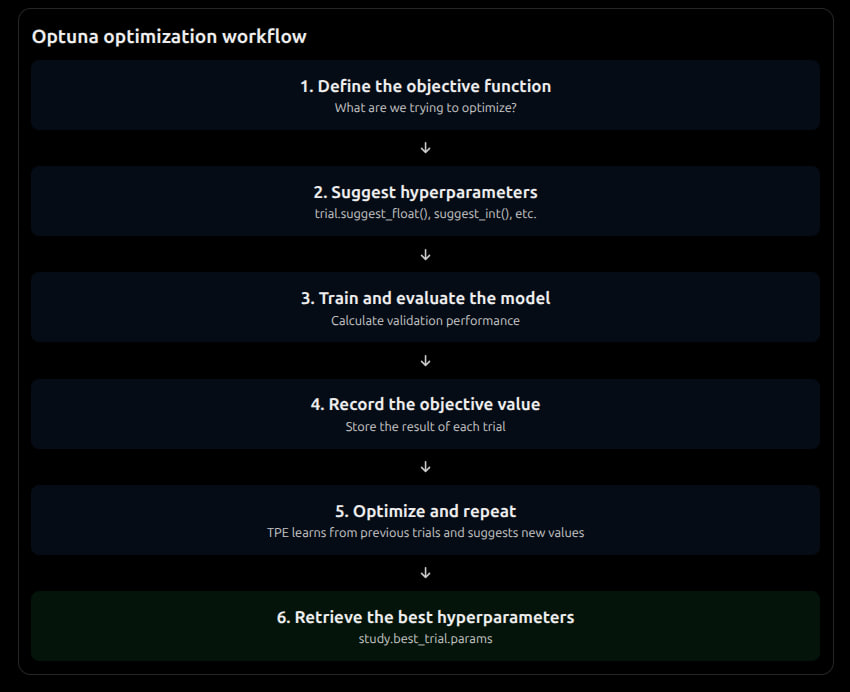

### 2: Optuna Dashboard 

 Optuna Dashboard is a web-based graphical user interface (GUI) that allows you to monitor and analyze hyperparameter optimization studies.

**Main advantage: It makes optimization experiments easier to understand, monitor, and analyze without manually writing visualization code.**

**The dashboard display the following information:**

|Feature | Explanation |
|---|---|
|Optimization History | Shows how the objective value changes across trials. |
|Parameter Importance | Identifies which hyperparameters influence the objective most. |
|Parallel Coordinate Plot | Shows relationships between multiple hyperparameters and their results. |
|Slice Plot | Shows how individual parameter values relate to objective values. |
|Trial Information | Displays trial status, parameters, values, and duration. |
|Study Comparison | Helps compare different optimization studies. |

**2.1. The basic workflow:**

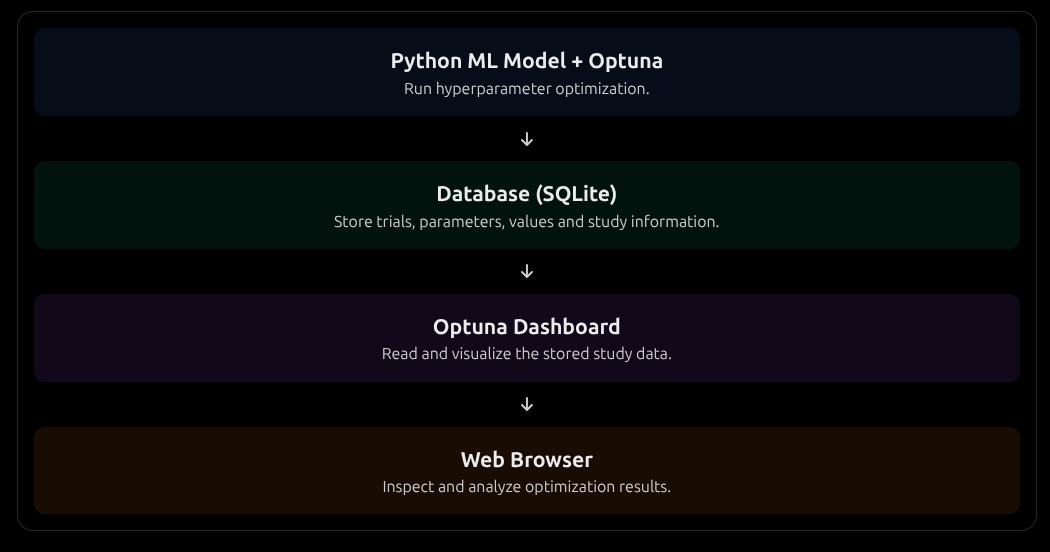

**2.2. Storage Backedn Concept:**

An important concept here is the storage backend.

Optuna Dashboard does not need to run inside your training code. It connects to the same database where Optuna stores the optimization results.

For example, SQLite stores the study data in a local database file called **optuna.db**.

**2.3. Implementation:**

Install the package using: 
**pip install optuna optuna-dashboard**

In [ ]:
# Define the objective function
def objective(trial):

    # Suggest hyperparameter values
    x = trial.suggest_float("x", -10, 10)
    y = trial.suggest_float("y", -10, 10)

    # Calculate the objective value
    return (x - 3)**2 + (y + 2)**2


# Create a persistent study with storage definition to retrive data from it
study = optuna.create_study(
    study_name="dashboard_demo",
    storage="sqlite:///optuna.db",
    direction="minimize",
    load_if_exists=True
)

# Run 100 optimization trials
study.optimize(objective, n_trials=100)

print("Best parameters:", study.best_params)
print("Best objective value:", study.best_value)


#Understanding the important parts:
# - sqlite:///optuna.db: Tells Optuna to save the study in an SQLite database.
# - study_name: Gives the optimization study a name.
# - direction="minimize": Tells Optuna to find the lowest objective value.
# - load_if_exists=True: Reuses an existing study with the same name and storage.
# - n_trials=100: Runs 100 optimization attempts.

[I 2026-11-22 19:48:17,555] A new study created in RDB with name: dashboard_demo
[I 2026-11-22 19:48:18,983] Trial 0 finished with value: 97.68901147149643 and parameters: {'x': 4.3504882119281145, 'y': 7.791077216575285}. Best is trial 0 with value: 97.68901147149643.
[I 2026-11-22 19:48:20,240] Trial 1 finished with value: 100.23123303618259 and parameters: {'x': 1.1970358708189117, 'y': 7.847870500015162}. Best is trial 0 with value: 97.68901147149643.
[I 2026-11-22 19:48:21,603] Trial 2 finished with value: 76.67716774864768 and parameters: {'x': -5.227589112947237, 'y': 0.9973229951341196}. Best is trial 2 with value: 76.67716774864768.
[I 2026-11-22 19:48:23,151] Trial 3 finished with value: 15.567978287973636 and parameters: {'x': 1.7289157550848984, 'y': -5.735280863643622}. Best is trial 3 with value: 15.567978287973636.
[I 2026-11-22 19:48:24,828] Trial 4 finished with value: 90.64005890904102 and parameters: {'x': -6.2452492081179845, 'y': 0.2727573537082222}. Best is trial 

Best parameters: {'x': 3.18976575483848, 'y': -2.04088817009795}
Best objective value: 0.037682884163377055


In the terminal run: optuna-dashboard sqlite:///optuna.db

In browser run: http://127.0.0.1:8080